In [2]:
%pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Importando bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [8]:
# Carregando e limpando os dados
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Removendo o ID do cliente (não será necessário para prever comportamento)
df.drop('customerID', axis=1, inplace=True)

# Corrigindo espaços em branco na coluna de Total Gasto e converter para número
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

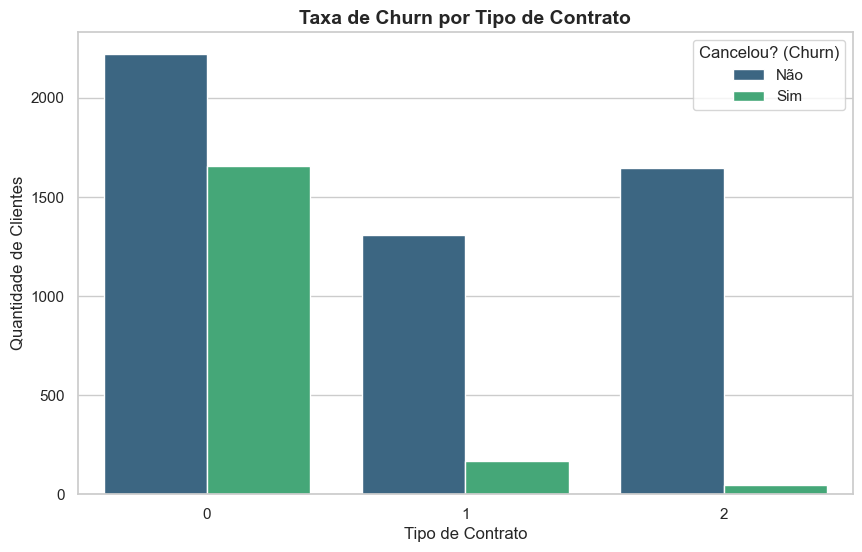

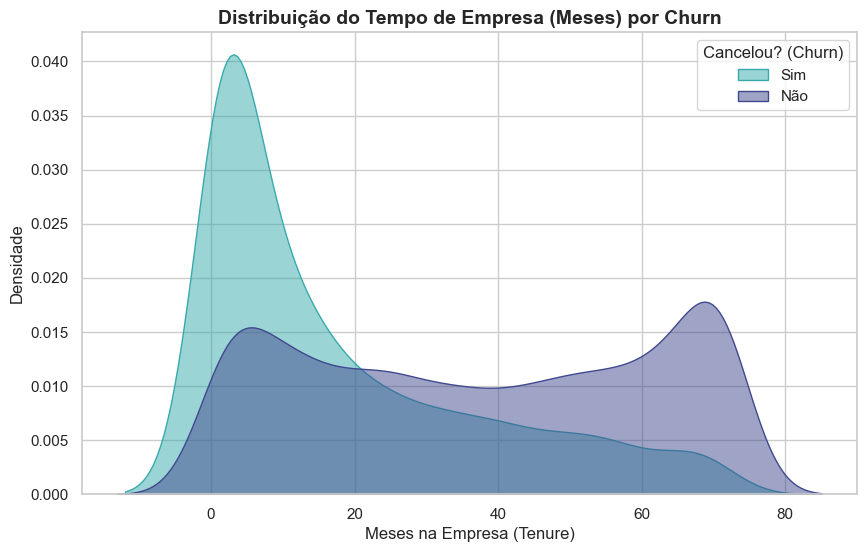

In [15]:
# Configurando o estilo dos gráficos
sns.set_theme(style="whitegrid")

# 1. Gráfico de Churn por Tipo de Contrato
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Contract', hue='Churn', palette='viridis')
plt.title('Taxa de Churn por Tipo de Contrato', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Contrato', fontsize=12)
plt.ylabel('Quantidade de Clientes', fontsize=12)
plt.legend(title='Cancelou? (Churn)', labels=['Não', 'Sim'])
# Salva a imagem no seu computador/colab
plt.savefig('churn_por_contrato.png', bbox_inches='tight', dpi=300)
plt.show()

# 2. Gráfico de Distribuição do Tempo de Empresa (Tenure)
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, common_norm=False, palette='mako', alpha=0.5)
plt.title('Distribuição do Tempo de Empresa (Meses) por Churn', fontsize=14, fontweight='bold')
plt.xlabel('Meses na Empresa (Tenure)', fontsize=12)
plt.ylabel('Densidade', fontsize=12)
plt.legend(title='Cancelou? (Churn)', labels=['Sim', 'Não'])
plt.savefig('churn_por_tempo.png', bbox_inches='tight', dpi=300)
plt.show()


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


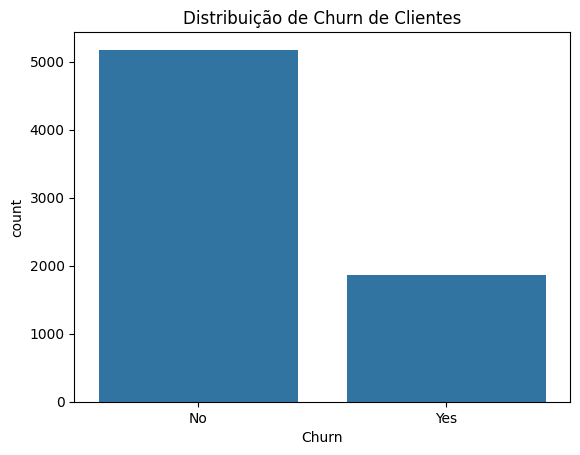

In [9]:
# Análise Exploratória de Dados (EDA)
# Clientes que saíram X Clientes que ficaram
# Ver a distribuição de Churn
print(df['Churn'].value_counts(normalize=True))

# Gráfico para o portfólio
sns.countplot(x='Churn', data=df)
plt.title('Distribuição de Churn de Clientes')
plt.show()

In [11]:
# Transformando texto em números (Encoding)
# Identificando colunas de texto
colunas_textos = df.select_dtypes(include=['object']).columns

# Transformar texto em números dinamicamente
le = LabelEncoder()
for col in colunas_textos:
    df[col] = le.fit_transform(df[col])

C:\Users\Magna Oliveira\AppData\Local\Temp\ipykernel_728\3902024764.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_textos = df.select_dtypes(include=['object']).columns


In [12]:
# Separando os dados para Treino e Teste
# X = características do cliente / Y = o que prever (Churn)
x = df.drop('Churn', axis=1)
y = df['Churn']

# Divisão
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


In [13]:
# Treinando a IA
# Criando o modelo (Random Forest)
modelo = RandomForestClassifier(random_state=42)

# Treinando o modelo
modelo.fit(x_train, y_train)

# Fazendo as previsões nnos dados de teste
previsoes = modelo.predict(x_test)

In [14]:
# Avaliando os resultados
# Imprimindo o relatório completo de métricas
print(classification_report(y_test, previsoes))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.47      0.55       373

    accuracy                           0.80      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.80      0.78      1409

